In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [16]:
iris = load_iris()

X = iris.data
y = iris.target

print("Kích thước dữ liệu:", X.shape)
print("Số lượng nhãn:", y.shape)

print("Tên các loại hoa:", iris.target_names)

Kích thước dữ liệu: (150, 4)
Số lượng nhãn: (150,)
Tên các loại hoa: ['setosa' 'versicolor' 'virginica']


In [17]:
test_sizes = [0.2, 0.3, 0.4, 0.5]

results = []

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Khởi tạo mô hình SVM
    svm_model = SVC(kernel='linear')

    # Huấn luyện mô hình
    svm_model.fit(X_train_scaled, y_train)

    # Dự đoán
    y_pred = svm_model.predict(X_test_scaled)

    # Đánh giá
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Tỷ lệ kiểm tra': f'{int(test_size*100)}%',
        'Tập huấn luyện': len(X_train),
        'Tập kiểm tra': len(X_test),
        'Accuracy': accuracy
    })

    print(f"\nTỷ lệ kiểm tra: {int(test_size*100)}%")
    print(f"Accuracy: {accuracy:.4f}")
    print("Ma trận nhầm lẫn:")
    print(confusion_matrix(y_test, y_pred))

    print("Báo cáo phân loại:")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names
    ))


Tỷ lệ kiểm tra: 20%
Accuracy: 1.0000
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Tỷ lệ kiểm tra: 30%
Accuracy: 0.9111
Ma trận nhầm lẫn:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45


Tỷ lệ kiểm tr

In [18]:
results_df = pd.DataFrame(results)

print("BẢNG SO SÁNH KẾT QUẢ SVM")
print(results_df)

BẢNG SO SÁNH KẾT QUẢ SVM
  Tỷ lệ kiểm tra  Tập huấn luyện  Tập kiểm tra  Accuracy
0            20%             120            30  1.000000
1            30%             105            45  0.911111
2            40%              90            60  0.950000
3            50%              75            75  0.973333


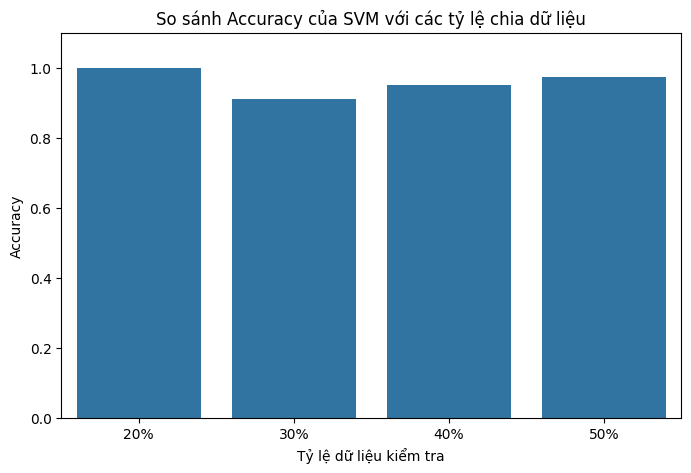

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x='Tỷ lệ kiểm tra',
    y='Accuracy'
)

plt.title('So sánh Accuracy của SVM với các tỷ lệ chia dữ liệu')
plt.xlabel('Tỷ lệ dữ liệu kiểm tra')
plt.ylabel('Accuracy')
plt.ylim(0, 1.1)

plt.show()

In [20]:
best_result = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Cách chia dữ liệu tốt nhất:")
print(best_result)

Cách chia dữ liệu tốt nhất:
Tỷ lệ kiểm tra    20%
Tập huấn luyện    120
Tập kiểm tra       30
Accuracy          1.0
Name: 0, dtype: object
